<a href="https://colab.research.google.com/github/claragarciaperez/Open_Quantum_Systems_RI/blob/main/qiskit_bosonicbath.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from qiskit import transpile, QuantumCircuit
from qiskit_aer import AerSimulator
import qiskit.quantum_info as qi
from qiskit.visualization import plot_histogram
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)


# No noise

In [ ]:
def sz_2_nonoise_circuit(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5,omega = 0.5, omega_A = 0.25):
  sz_2_nonoise = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)
    results = job.result().get_counts()
    valor = (results.get('0',0) - ((results.get('1',0)))) / nshots
    sz_2_nonoise.append(-valor)
  return sz_2_nonoise

In [ ]:
def sx_2_nonoise_circuit(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5,omega = 0.5, omega_A = 0.25):
  sx_2_nonoise = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.h(0)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)


    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sx_2_nonoise.append(valor)
  return sx_2_nonoise

In [ ]:
def sy_2_nonoise_circuit(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5,omega = 0.5, omega_A = 0.25):
  sy_2_nonoise = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.qubits
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.sdg(0)
    qc.h(0)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)

    results = job.result().get_counts()
    valor = (results.get('0', 0) - (results.get('1', 0))) / nshots
    sy_2_nonoise.append(-valor)
  return sy_2_nonoise

In [ ]:
def ps_nonoise_2(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5,omega = 0.5, omega_A = 0.25):
  ps = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.x(2)
    qc.rxx(alpha,1,2)
    qc.ryy(alpha,1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.x(2)
      qc.rxx(alpha,1,2)
      qc.ryy(alpha,1,2)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)

    results = job.result().get_counts()
    ps_value = (results.get('0', 0)) / nshots
    ps.append(ps_value)
  return ps

In [ ]:
def ps_nonoise(simulator_aer,alpha, N = 30, g = 0.7, delta_t = 0.5, omega = 0.5, omega_A=0.25):
  ps = []
  for niter in range(0,N+1):
    qc = QuantumCircuit(3,1)
    qc.ry(np.pi-np.pi/3,0)
    qc.rz(-np.pi/3,0)
    qc.ry(alpha,1)
    qc.cx(1,2)
    for i in range(0,niter):
      qc.rz(-omega_A*delta_t,1)
      qc.rxx(g*delta_t,0,1)
      qc.ryy(g*delta_t,0,1)
      qc.rz(-omega*delta_t,0)
      qc.reset(1)
      qc.reset(2)
      qc.ry(alpha,1)
      qc.cx(1,2)
    qc.measure(0,0)

    job = simulator_aer.run(qc,shots = nshots)

    results = job.result().get_counts()
    ps_value = (results.get('0', 0)) / nshots
    ps.append(ps_value)
  return ps


In [ ]:
Gamma = 0.25
delta_t = 0.1

omega = 0.5
N = int(25/delta_t)
nshots = 1024

omega_A = omega


0.1
sx done
sy done
sz done
0.5
sx done
sy done
sz done
1
sx done
sy done
sz done


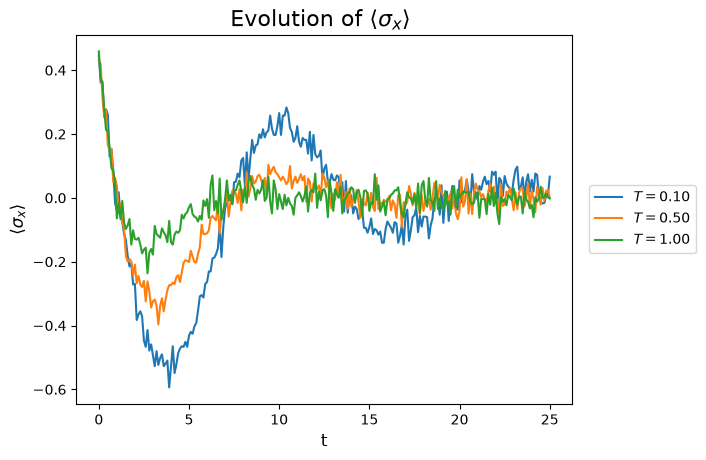

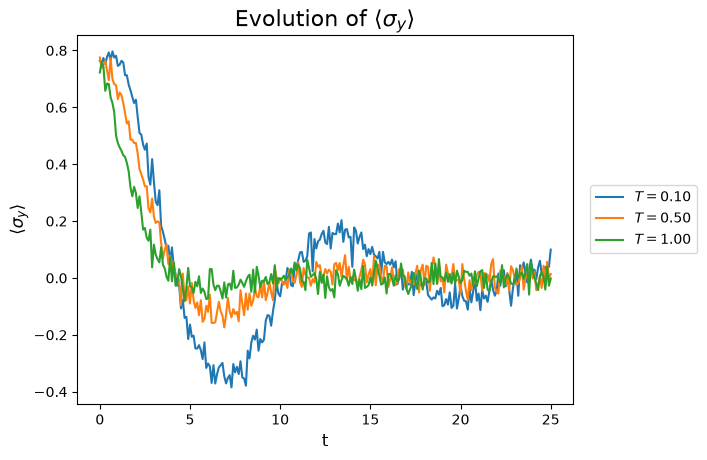

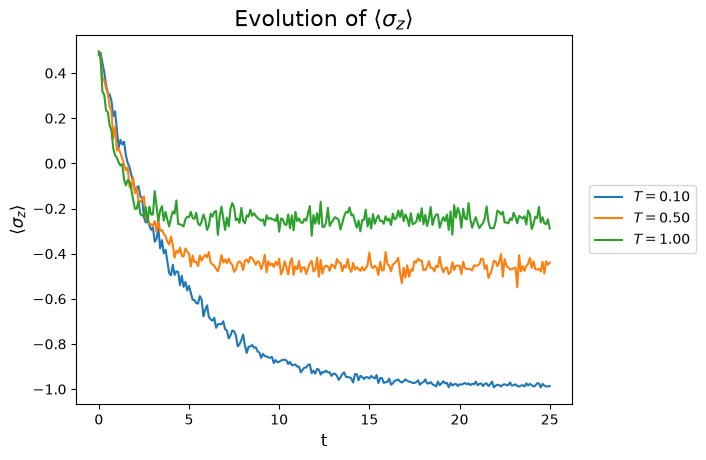

In [ ]:
simulator_aer = AerSimulator()
fig_x, ax_x = plt.subplots()
fig_y, ax_y = plt.subplots()
fig_z, ax_z = plt.subplots()
time = np.arange(N+1) * delta_t

for T in [ 0.1, 0.5, 1]:
  print(T)
  beta = 1/T
  alpha = 2*np.acos(np.sqrt(1/(1+np.exp(-beta*omega_A))))
  n_B = 1/(np.exp(omega_A/T)-1)
  g = np.sqrt(Gamma*(2*n_B+1)/delta_t)
  sx_2_nonoise = sx_2_nonoise_circuit(simulator_aer,alpha, N,g,delta_t)
  print('sx done')
  sy_2_nonoise= sy_2_nonoise_circuit(simulator_aer,alpha, N,g,delta_t)
  print('sy done')
  sz_2_nonoise= sz_2_nonoise_circuit(simulator_aer,alpha, N,g,delta_t)
  print('sz done')
  ax_x.plot(time, sx_2_nonoise, label=rf'$T ={T:.2f}$')
  ax_y.plot(time, sy_2_nonoise, label=rf'$T ={T:.2f}$')
  ax_z.plot(time, sz_2_nonoise, label=rf'$T ={T:.2f}$')

  datos = np.column_stack((time, sx_2_nonoise, sy_2_nonoise, sz_2_nonoise))

  np.savetxt(
  f"qiskit_thermalstatebosonic_sz_ns1024_nonoise_T_{T:.2f}_dt_{delta_t:.2f}_omegaA_{omega_A}.txt",
  datos,
  header="t sx sy sz",
  fmt="%.10f"
  )



ax_x.set_xlabel('t', fontsize = 12)
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$', fontsize = 12)
ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$ ', fontsize = 16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

# Configurar figura de Y
ax_y.set_xlabel('t', fontsize = 12)
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$', fontsize = 12)
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$', fontsize = 16)
ax_y.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

# Configurar figura de Z
ax_z.set_xlabel('t', fontsize = 12)
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$', fontsize = 12)
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$', fontsize = 16)
ax_z.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))
plt.show()

#plt.plot(time, sx_2_nonoise,label=rf'$\langle \sigma_x\rangle$')
#plt.plot(time, sy_2_nonoise,label=rf'$\langle \sigma_y\rangle$')
#plt.plot(time, sz_2_nonoise,label=rf'$\langle \sigma_z\rangle$')

#plt.xlabel('t')
#plt.ylabel('Expected Value')
#plt.legend()


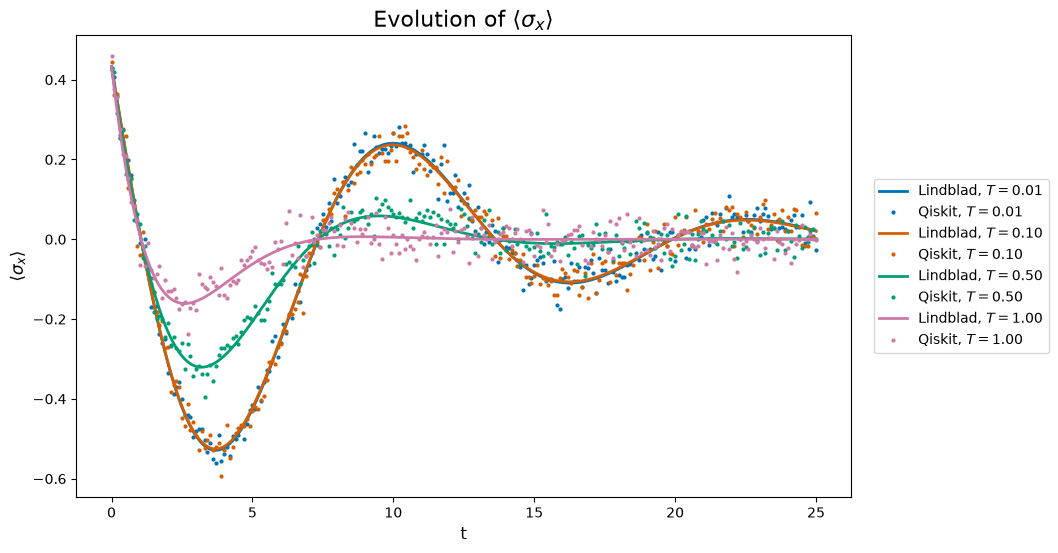

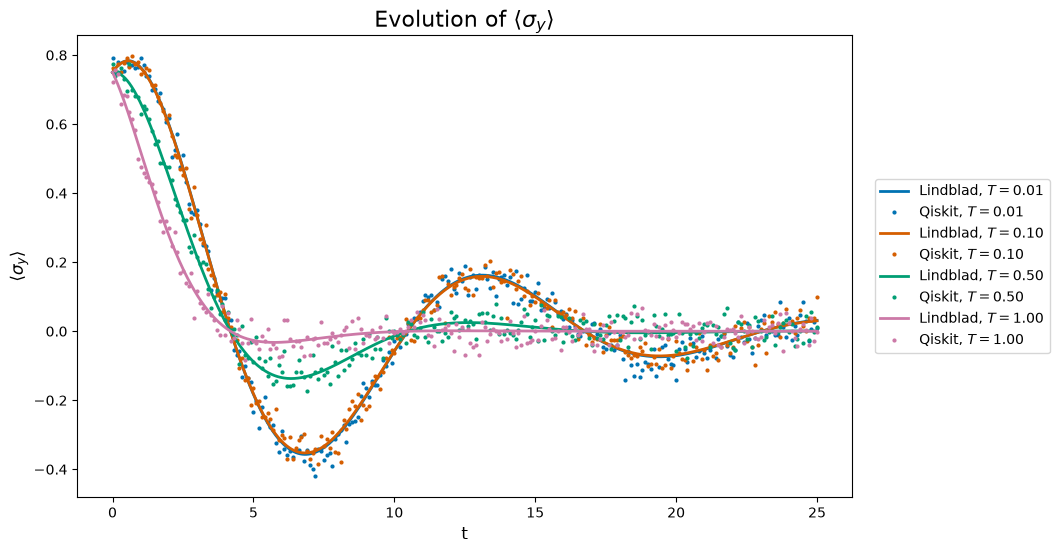

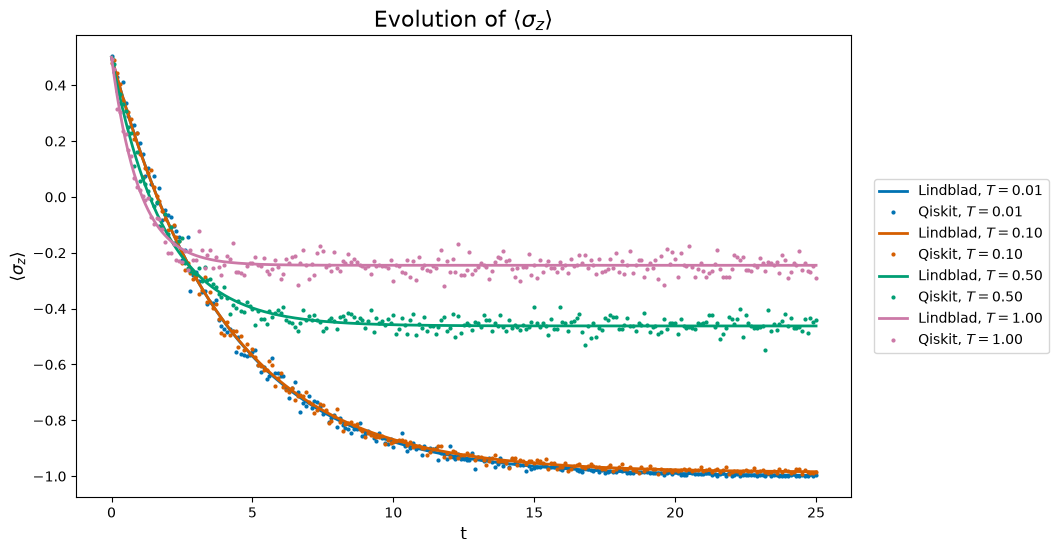

In [ ]:
delta_t = 0.1

fig_x, ax_x = plt.subplots(figsize=(10, 6))
fig_y, ax_y = plt.subplots(figsize=(10, 6))
fig_z, ax_z = plt.subplots(figsize=(10, 6))

temperatures = [0.01, 0.1, 0.5, 1]

colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7']

for T, color in zip(temperatures, colors):

    filename = f"qiskit_thermalstatebosonic_sz_ns1024_nonoise_T_{T:.2f}_dt_{delta_t:.2f}_omegaA_{omega_A}.txt"
    file2 = f"linblad_Gamma_{Gamma}_omegas_{omega}_omegaA_{omega_A}_T_{T:.2f}.txt"

    datos = np.loadtxt(filename, skiprows=1)
    datos2 = np.loadtxt(file2, skiprows=1)

    # Qiskit
    time = datos[:, 0]
    sx_qiskit = datos[:, 1]
    sy_qiskit = datos[:, 2]
    sz_qiskit = datos[:, 3]

    # Lindblad
    time2 = datos2[:, 0]
    sx_lindblad = datos2[:, 1]
    sy_lindblad = datos2[:, 2]
    sz_lindblad = datos2[:, 3]

    # Sigma X
    ax_x.plot(time2, sx_lindblad, color=color, linestyle='-',
              linewidth=2, label=rf'Lindblad, $T={T:.2f}$')

    ax_x.plot(time, sx_qiskit, color=color, linestyle='none',
              marker='.', markersize=4,
              label=rf'Qiskit, $T={T:.2f}$')

    # Sigma Y
    ax_y.plot(time2, sy_lindblad, color=color, linestyle='-',
              linewidth=2, label=rf'Lindblad, $T={T:.2f}$')

    ax_y.plot(time, sy_qiskit, color=color, linestyle='none',
              marker='.', markersize=4,
              label=rf'Qiskit, $T={T:.2f}$')

    # Sigma Z
    ax_z.plot(time2, sz_lindblad, color=color, linestyle='-',
              linewidth=2, label=rf'Lindblad, $T={T:.2f}$')

    ax_z.plot(time, sz_qiskit, color=color, linestyle='none',
              marker='.', markersize=4,
              label=rf'Qiskit, $T={T:.2f}$')


# Configuración X
ax_x.set_xlabel('t', fontsize=12)
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$', fontsize=12)
ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$', fontsize=16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


# Configuración Y
ax_y.set_xlabel('t', fontsize=12)
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$', fontsize=12)
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$', fontsize=16)
ax_y.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


# Configuración Z
ax_z.set_xlabel('t', fontsize=12)
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$', fontsize=12)
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$', fontsize=16)
ax_z.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

plt.show()

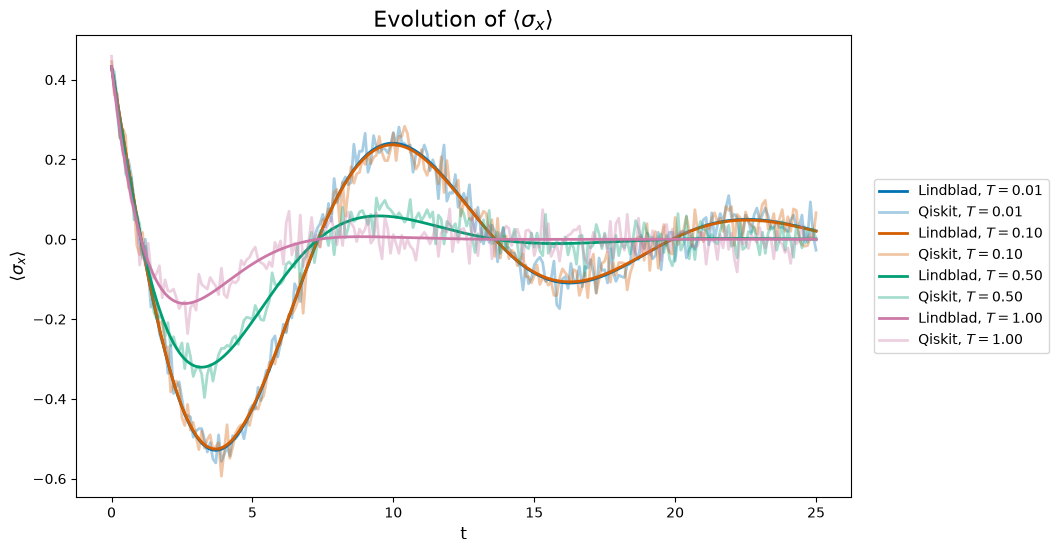

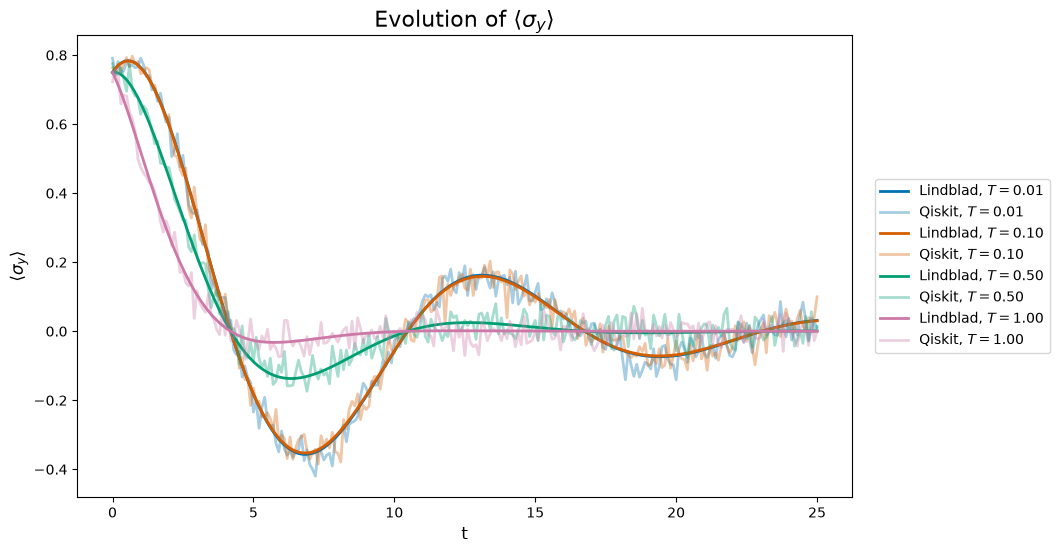

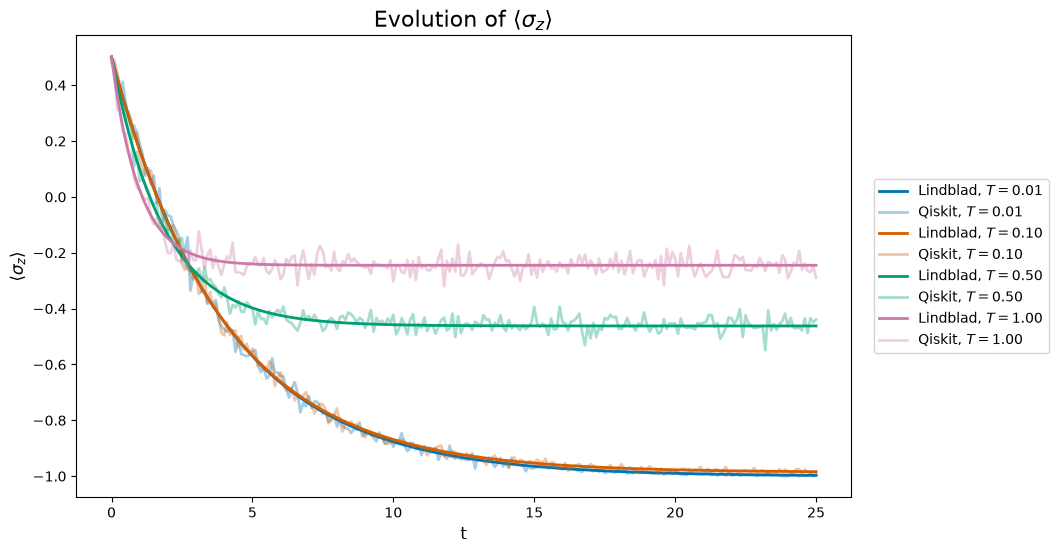

In [ ]:
delta_t = 0.1

fig_x, ax_x = plt.subplots(figsize=(10, 6))
fig_y, ax_y = plt.subplots(figsize=(10, 6))
fig_z, ax_z = plt.subplots(figsize=(10, 6))

temperatures = [0.01, 0.1, 0.5, 1]

colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7']

for T, color in zip(temperatures, colors):

    filename = f"qiskit_thermalstatebosonic_sz_ns1024_nonoise_T_{T:.2f}_dt_{delta_t:.2f}_omegaA_{omega_A}.txt"
    file2 = f"linblad_Gamma_{Gamma}_omegas_{omega}_omegaA_{omega_A}_T_{T:.2f}.txt"

    datos = np.loadtxt(filename, skiprows=1)
    datos2 = np.loadtxt(file2, skiprows=1)

    # Qiskit
    time = datos[:, 0]
    sx_qiskit = datos[:, 1]
    sy_qiskit = datos[:, 2]
    sz_qiskit = datos[:, 3]

    # Lindblad
    time2 = datos2[:, 0]
    sx_lindblad = datos2[:, 1]
    sy_lindblad = datos2[:, 2]
    sz_lindblad = datos2[:, 3]

    # Sigma X
    ax_x.plot(time2, sx_lindblad, color=color, linestyle='-',
              linewidth=2, alpha=1,
              label=rf'Lindblad, $T={T:.2f}$')

    ax_x.plot(time, sx_qiskit, color=color, linestyle='-',
              linewidth=2, alpha=0.35,
              label=rf'Qiskit, $T={T:.2f}$')

    # Sigma Y
    ax_y.plot(time2, sy_lindblad, color=color, linestyle='-',
              linewidth=2, alpha=1,
              label=rf'Lindblad, $T={T:.2f}$')

    ax_y.plot(time, sy_qiskit, color=color, linestyle='-',
              linewidth=2, alpha=0.35,
              label=rf'Qiskit, $T={T:.2f}$')

    # Sigma Z
    ax_z.plot(time2, sz_lindblad, color=color, linestyle='-',
              linewidth=2, alpha=1,
              label=rf'Lindblad, $T={T:.2f}$')

    ax_z.plot(time, sz_qiskit, color=color, linestyle='-',
              linewidth=2, alpha=0.35,
              label=rf'Qiskit, $T={T:.2f}$')


# Configuración X
ax_x.set_xlabel('t', fontsize=12)
ax_x.set_ylabel(r'$\langle \sigma_x \rangle$', fontsize=12)
ax_x.set_title(r'Evolution of $\langle \sigma_x \rangle$', fontsize=16)
ax_x.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


# Configuración Y
ax_y.set_xlabel('t', fontsize=12)
ax_y.set_ylabel(r'$\langle \sigma_y \rangle$', fontsize=12)
ax_y.set_title(r'Evolution of $\langle \sigma_y \rangle$', fontsize=16)
ax_y.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))


# Configuración Z
ax_z.set_xlabel('t', fontsize=12)
ax_z.set_ylabel(r'$\langle \sigma_z \rangle$', fontsize=12)
ax_z.set_title(r'Evolution of $\langle \sigma_z \rangle$', fontsize=16)
ax_z.legend(loc='center left', bbox_to_anchor=(1.02, 0.5))

plt.show()

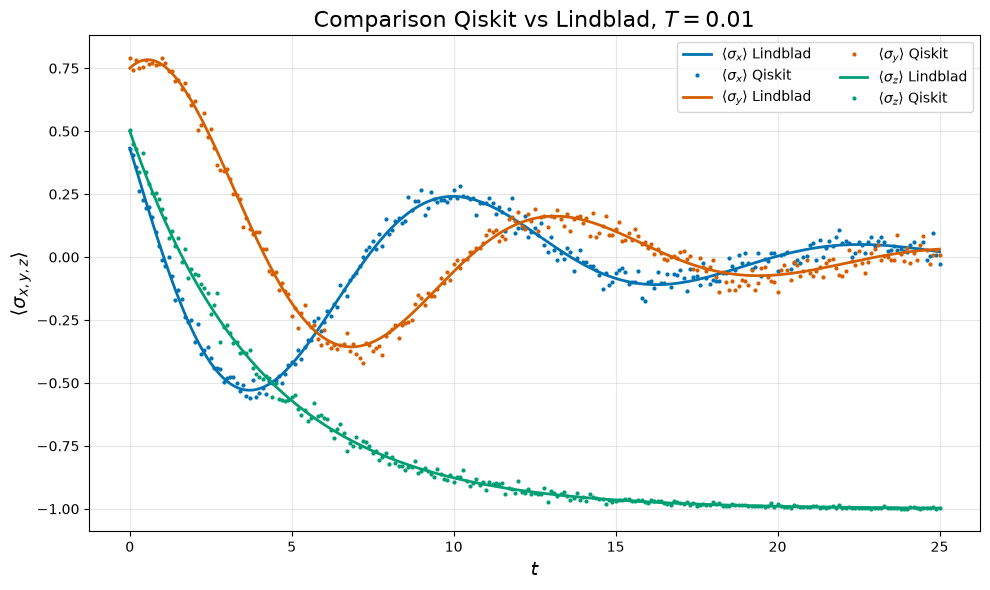

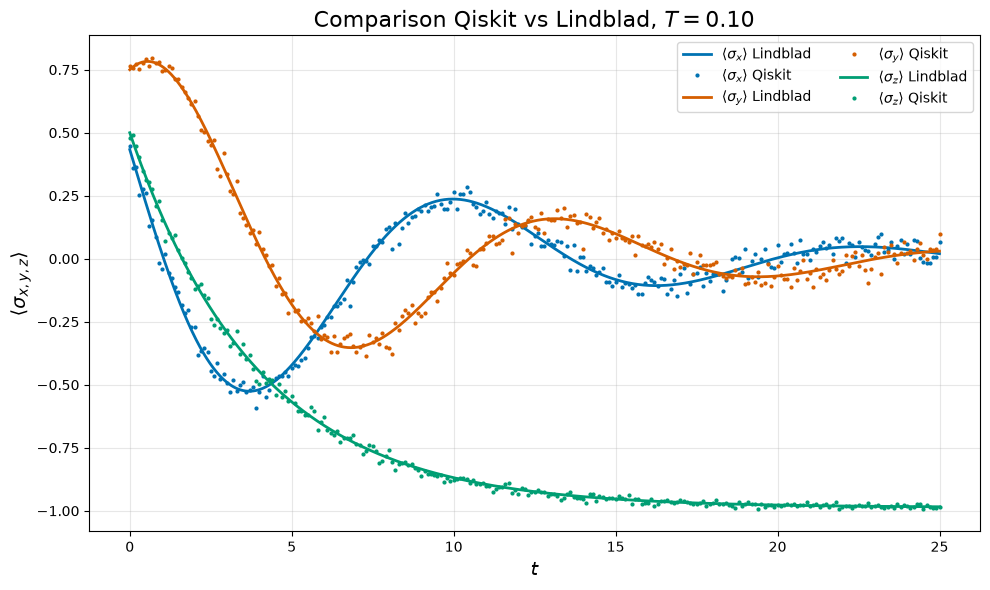

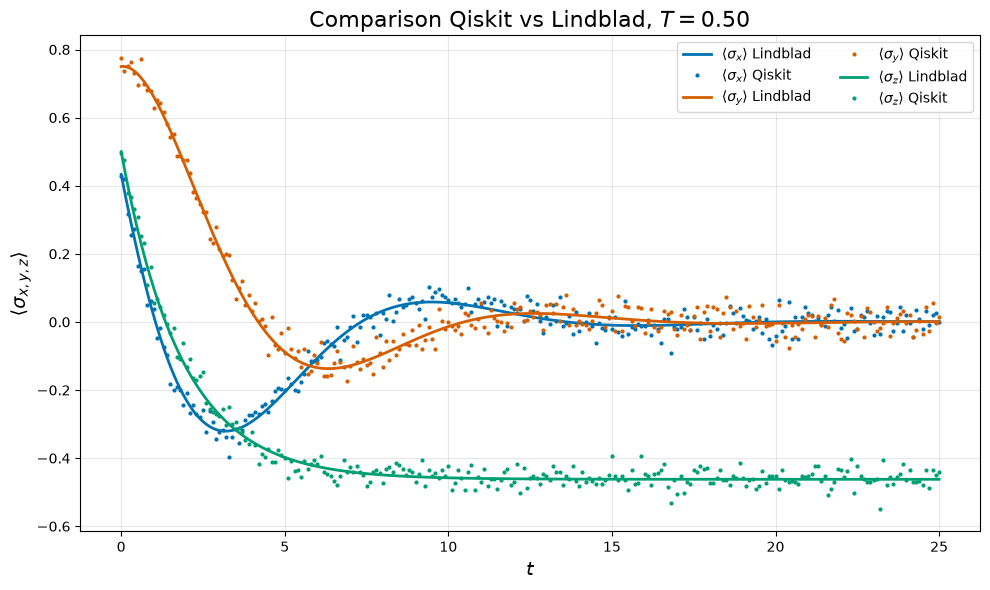

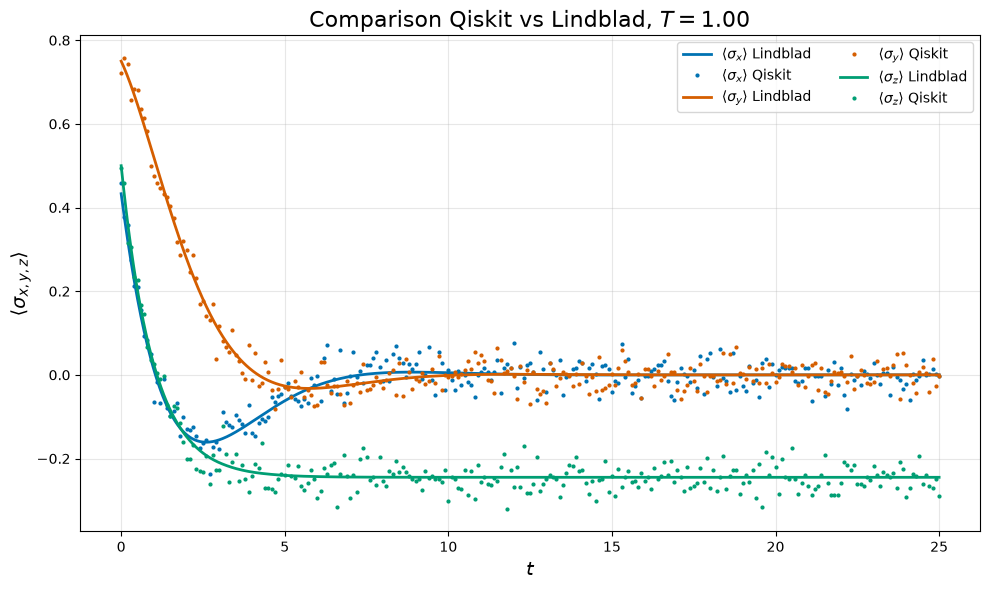

In [ ]:
delta_t = 0.1

temperatures = [0.01, 0.1, 0.5, 1]
colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7']

for T, color in zip(temperatures, colors):

    filename = f"qiskit_thermalstatebosonic_sz_ns1024_nonoise_T_{T:.2f}_dt_{delta_t:.2f}_omegaA_{omega_A}.txt"
    file2 = f"linblad_Gamma_{Gamma}_omegas_{omega}_omegaA_{omega_A}_T_{T:.2f}.txt"

    datos = np.loadtxt(filename, skiprows=1)
    datos2 = np.loadtxt(file2, skiprows=1)

    # Qiskit
    time = datos[:, 0]
    sx_qiskit = datos[:, 1]
    sy_qiskit = datos[:, 2]
    sz_qiskit = datos[:, 3]

    # Lindblad
    time2 = datos2[:, 0]
    sx_lindblad = datos2[:, 1]
    sy_lindblad = datos2[:, 2]
    sz_lindblad = datos2[:, 3]

    # Una única figura
    fig, ax = plt.subplots(figsize=(10, 6))

    # Sigma X
    # Sigma X
    ax.plot(time2, sx_lindblad, color='#0072B2',
                linestyle='-', linewidth=2,
                label=r'$\langle \sigma_x \rangle$ Lindblad')
    ax.plot(time, sx_qiskit, color='#0072B2',
                linestyle='none', marker='.', markersize=4,
                label=r'$\langle \sigma_x \rangle$ Qiskit')
    ax.plot(time2, sy_lindblad, color='#D55E00',
                linestyle='-', linewidth=2,
                label=r'$\langle \sigma_y \rangle$ Lindblad')
    ax.plot(time, sy_qiskit, color='#D55E00',
                linestyle='none', marker='.', markersize=4,
        label=r'$\langle \sigma_y \rangle$ Qiskit')
    ax.plot(time2, sz_lindblad, color='#009E73',
                linestyle='-', linewidth=2,
                label=r'$\langle \sigma_z \rangle$ Lindblad')
    ax.plot(time, sz_qiskit, color='#009E73',
                linestyle='none', marker='.', markersize=4,
                label=r'$\langle \sigma_z \rangle$ Qiskit')

    ax.set_xlabel(r'$t$', fontsize=14)
    ax.set_ylabel(r'$\langle \sigma_{x,y,z} \rangle$', fontsize=14)

    ax.set_title(rf'Comparison Qiskit vs Lindblad, $T={T:.2f}$',
                 fontsize=16)

    ax.legend(fontsize=10, ncol=2)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()